In [8]:
import pandas as pd
import numpy as np
import patsy
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.stats.multicomp as mc
import scipy.stats as stats
from statsmodels.formula.api import ols
from pingouin import ancova

In [9]:
data = {
    'Parcela' : ['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10', 'P11', 'P12'],
    'Tratamiento': ["Ninguno", "Fert_A", "Fert_B", "Fert_C",
                    "Ninguno", "Fert_A", "Fert_B", "Fert_C",
                    "Ninguno", "Fert_A", "Fert_B", "Fert_C"],
    'Rendimiento' : [480, 500, 600, 550, 465, 525, 620, 575, 470, 490, 690, 560]
}

df = pd.DataFrame(data)
print(df)

   Parcela Tratamiento  Rendimiento
0       P1     Ninguno          480
1       P2      Fert_A          500
2       P3      Fert_B          600
3       P4      Fert_C          550
4       P5     Ninguno          465
5       P6      Fert_A          525
6       P7      Fert_B          620
7       P8      Fert_C          575
8       P9     Ninguno          470
9      P10      Fert_A          490
10     P11      Fert_B          690
11     P12      Fert_C          560


# Visualización

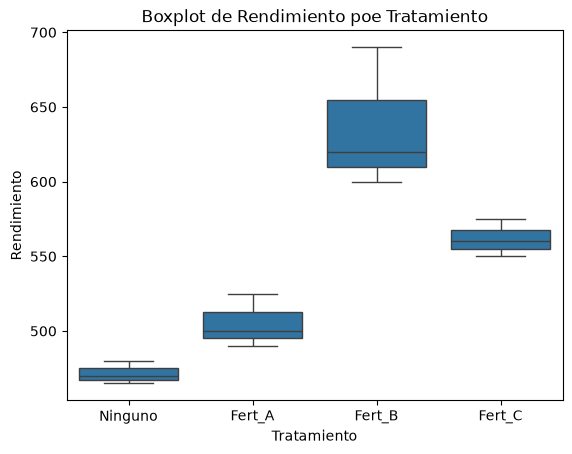

In [10]:
sns.boxplot(x = "Tratamiento", y = "Rendimiento", data = df)
plt.xticks(rotation = 0)
plt.title("Boxplot de Rendimiento poe Tratamiento")
plt.show()

# ANOVA

In [12]:
modelo = ols("Rendimiento ~ Tratamiento", data = df).fit()
anova_table = sm.stats.anova_lm(modelo, typ = 2)
print(anova_table)

               sum_sq   df          F    PR(>F)
Tratamiento  46956.25  3.0  22.561562  0.000294
Residual      5550.00  8.0        NaN       NaN


In [13]:
modelo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            Rendimiento   R-squared:                       0.894
Model:                            OLS   Adj. R-squared:                  0.855
Method:                 Least Squares   F-statistic:                     22.56
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           0.000294
Time:                        17:01:35   Log-Likelihood:                -53.847
No. Observations:                  12   AIC:                             115.7
Df Residuals:                       8   BIC:                             117.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                505.0000     15.207     33.209      0.000     469.933     540.067
Tratamiento[T.Fert_B]    131.6667     21.506      6.122      0.000      82.074     181.259
Tratamiento[T.Fert_C]     56.6667     21.506      2.635      0.030       7.074     106.259
Tratamiento[T.Ninguno]   -33.3333     21.506     -1.550      0.160     -82.926      16.259
==============================================================================
Omnibus:                        5.201   Durbin-Watson:                   2.321
Prob(Omnibus):                  0.074   Jarque-Bera (JB):                1.990
Skew:                           0.866   Prob(JB):                        0.370
Kurtosis:                       3.991   Cond. No.                         4.79
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

# Prueba de Tukey

In [14]:
comp = mc.MultiComparison(df['Rendimiento'], df['Tratamiento'])
post_hoc_res = comp.tukeyhsd()
print(post_hoc_res.summary())

  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1  group2 meandiff p-adj    lower    upper   reject
--------------------------------------------------------
Fert_A  Fert_B 131.6667 0.0013   62.7975 200.5359   True
Fert_A  Fert_C  56.6667 0.1113  -12.2025 125.5359  False
Fert_A Ninguno -33.3333 0.4546 -102.2025  35.5359  False
Fert_B  Fert_C    -75.0 0.0336 -143.8692  -6.1308   True
Fert_B Ninguno   -165.0 0.0003 -233.8692 -96.1308   True
Fert_C Ninguno    -90.0  0.013 -158.8692 -21.1308   True
--------------------------------------------------------
